# Pricing v2

In [1]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
from dotenv import load_dotenv
import os

In [2]:

load_dotenv()

USER_NAME = os.getenv("USER_NAME")
PASSWORD = os.getenv("PASSWORD")
HOST = os.getenv("HOST")
PORT = os.getenv("PORT")
DB_NAME = os.getenv("DB_NAME")

DATABASE_URL = rf"postgresql+psycopg2://{USER_NAME}:{PASSWORD}@{HOST}:{PORT}/{DB_NAME}"
engine = create_engine(DATABASE_URL)


In [3]:
sql = 'SELECT * FROM warehouse.vw_warehouse_sales; '
data = pd.read_sql(sql, con=engine)

In [4]:
pr_oi = 'Rice - Basmati'
data_oi = data[data['product']==pr_oi]
data_oi

,sales_key,week,start_date,product,sales_units,cost_of_goods_sold_cogs,inventory_level,demand_forecast,price_per_unit,gross_profit,operating_profit,revenue,inventory_turnover_ratio,gross_profit_margin,revenue_growth,modified_row,run_id
0,1,1,2020-01-01,Rice - Basmati,1153.0,21.84,2915.0,1242.0,29.29,8589.85,5362.48,33771.37,0.28,0.2544,0.0000,False,20261002135808273756
1,2,2,2020-01-08,Rice - Basmati,1108.0,21.69,3307.0,1149.0,27.30,6215.88,3593.65,30248.40,0.38,0.2055,-0.1043,False,20261002135808273756
2,3,3,2020-01-15,Rice - Basmati,1527.0,22.38,3280.0,1639.0,27.48,7787.70,2713.53,41961.96,0.46,0.1856,0.3872,False,20261002135808273756
3,4,4,2020-01-22,Rice - Basmati,1299.0,21.41,1981.0,1093.0,26.56,6689.85,2756.27,34501.44,0.40,0.1939,-0.1778,False,20261002135808273756
4,5,5,2020-01-29,Rice - Basmati,1346.0,21.69,3135.0,1424.0,26.27,6164.68,1804.61,35359.42,0.68,0.1743,0.0249,False,20261002135808273756
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255,256,256,2024-11-20,Rice - Basmati,1109.0,21.61,14068.0,1392.0,28.01,7097.60,4623.34,31063.09,0.09,0.2285,-0.0343,False,20261002135808273756
256,257,257,2024-11-27,Rice - Basmati,1175.0,21.90,12893.0,1058.0,27.88,7026.50,3682.09,32759.00,0.08,0.2145,0.0546,False,20261002135808273756
257,258,258,2024-12-04,Rice - Basmati,1276.0,22.10,11617.0,1212.0,28.24,7834.64,4488.11,36034.24,0.10,0.2174,0.1000,False,20261002135808273756
258,259,259,2024-12-11,Rice - Basmati,1191.0,21.80,12926.0,1069.0,26.88,6050.28,2677.29,32014.08,0.10,0.1890,-0.1116,False,20261002135808273756


In [19]:
data_oi['op_cost'] = data_oi['gross_profit'] - data_oi['operating_profit']

In [20]:
q= data_oi[['sales_units', 'op_cost']].drop_duplicates()
q

,sales_units,op_cost
0,1153.0,3227.37
1,1108.0,2622.23
2,1527.0,5074.17
3,1299.0,3933.58
4,1346.0,4360.07
...,...,...
255,1109.0,2474.26
256,1175.0,3344.41
257,1276.0,3346.53
258,1191.0,3372.99


In [7]:
from sklearn.preprocessing import normalize

In [21]:

qq = normalize(q, axis=0, norm='max')
qq[:5]

array([[0.62561042, 0.54997521],
       [0.60119371, 0.44685347],
       [0.82854042, 0.86468787],
       [0.70482908, 0.67032025],
       [0.73033098, 0.74299829]])

In [15]:
import matplotlib.pyplot as plt

Text(0, 0.5, 'op_cost')

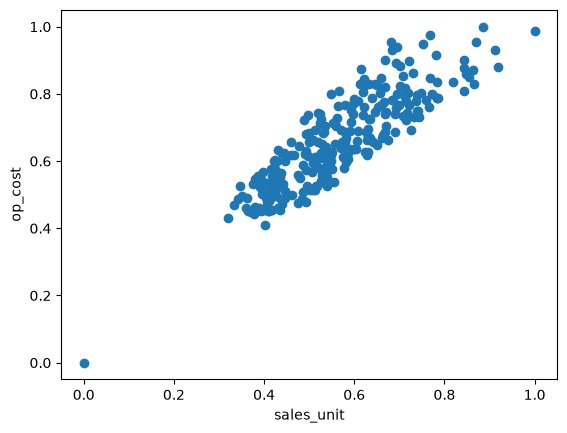

In [22]:
plt.scatter(qq[:, 1], qq[:, 0])
plt.xlabel('sales_unit')
plt.ylabel('op_cost')